In [24]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize


In [25]:

def european_call_payoff(S: float, K: float) -> float:
    # сalculate the payoff of a European Call option
    return max(S - K, 0.0)



# EN: Test the function with different stock prices
print(european_call_payoff(130, 100))
print(european_call_payoff(90, 100))
print(european_call_payoff(100, 100))


30
0.0
0


In [26]:

def create_spot_tree(spot, spot_mult_up, spot_mult_down, steps):
    #The first level contains only the current stock price
    previous_level = [spot]
    tree = [previous_level]

  
    #Create a new level for each time step
    for _ in range(steps):

    
        #Calculate stock prices after down movements
        new_level = [s * spot_mult_down for s in previous_level]

        # Add the last up movement
        new_level += [previous_level[-1] * spot_mult_up]

    
        #Add the new level to the tree
        tree += [new_level]
        
        #Use the new level in the next step
        previous_level = new_level

    return tree


In [27]:

spot_tree = create_spot_tree(100, 1.2, 0.8, 2)

for level in spot_tree:
    print(level)


[100]
[80.0, 120.0]
[64.0, 96.0, 144.0]


In [28]:

def calcBalancedDownStep(spot_mult_up, discount_factor):
    #Calculate the down multiplier for a balanced tree
    spot_mult_down = 2 / discount_factor - spot_mult_up

    return spot_mult_down


In [29]:

u = 1.2
discount_factor = 0.95

d = calcBalancedDownStep(u, discount_factor)

print("Up multiplier:", u)
print("Down multiplier:", d)


Up multiplier: 1.2
Down multiplier: 0.9052631578947368


In [30]:

def create_discounted_price_tree(spot_tree, discount_factor, K):

 
    #Get the initial stock price
    spot = spot_tree[0][0]

   
    #Сalculate the up and down multipliers
    spot_mult_up = spot_tree[1][-1] / spot
    spot_mult_down = spot_tree[1][0] / spot


    #Calculate risk-neutral probabilities
    p_up = ((1 / discount_factor - spot_mult_down) /
            (spot_mult_up - spot_mult_down))

    p_down = 1 - p_up


    #Number of time steps
    steps = len(spot_tree) - 1

    #Create an empty option price tree
    price_tree = [[0.0 for s in level] for level in spot_tree]

    #Calculate option payoffs at maturity
    for i in range(len(spot_tree[-1])):

        S = spot_tree[-1][i]

        # EN: Discount the final payoff to the initial time
        price_tree[-1][i] = (
            discount_factor ** steps *
            european_call_payoff(S, K)
        )

    #Move backwards through the tree
    for step in range(steps - 1, -1, -1):

        for i in range(len(spot_tree[step])):

            #Calculate the expected discounted option value
            price_tree[step][i] = (
                p_down * price_tree[step + 1][i] +
                p_up * price_tree[step + 1][i + 1]
            )

    return price_tree


In [31]:

spot = 100
K = 100
steps = 2
discount_factor = 0.95
u = 1.2

d = calcBalancedDownStep(u, discount_factor)

spot_tree = create_spot_tree(spot, u, d, steps)

price_tree = create_discounted_price_tree(
    spot_tree, discount_factor, K
)

print("Call price:", price_tree[0][0])


Call price: 13.822500000000003


In [32]:

from scipy.optimize import brentq

def calibrate(spot, K, T, r, steps, market_price):

    #Calculate the length of one time step
    dt = T / steps

    #Calculate the discount factor
    discount_factor = np.exp(-r * dt)

    #Risk-free growth factor
    a = 1 / discount_factor

    #Difference between model and market prices
    def price_difference(u):

        # Сalculate the down multiplier
        d = calcBalancedDownStep(u, discount_factor)

        #Create the stock price tree
        spot_tree = create_spot_tree(spot, u, d, steps)

        #Calculate the option price
        price_tree = create_discounted_price_tree(
            spot_tree, discount_factor, K
        )

        model_price = price_tree[0][0]

        #Return the difference between prices
        return model_price - market_price

    #Set valid bounds for u
    lower_bound = a + 1e-8
    upper_bound = 2 * a - 1e-8

    # сheck that the root is between the bounds
    if price_difference(lower_bound) * price_difference(upper_bound) > 0:
        raise ValueError("Target price is outside the calibration range")

    #Find u where the price difference equals zero
    u = brentq(
        price_difference,
        lower_bound,
        upper_bound
    )

    return u


In [33]:
#Test calibration for different numbers of steps

steps_list = [2, 5, 10, 20, 50]

calibrated_u = []

for steps in steps_list:

    #Find the calibrated up multiplier
    u = calibrate(100, 100, 1, 0.05, steps, 12.0)

    calibrated_u.append(u)

    print("Steps:", steps, "Calibrated u:", round(u, 6))


Steps: 2 Calibrated u: 1.213687
Steps: 5 Calibrated u: 1.113791
Steps: 10 Calibrated u: 1.08169
Steps: 20 Calibrated u: 1.05635
Steps: 50 Calibrated u: 1.035004


In [34]:

#Different option contract parameters

contracts = [
    [100, 95, 1.0, 0.05, 12.0],
    [100, 100, 0.5, 0.03, 12.0],
    [100, 105, 1.0, 0.05, 12.0]
]

steps = 20

for contract in contracts:

    spot, K, T, r, market_price = contract

#Calibrate the tree for each contract
    u = calibrate(spot, K, T, r, steps, market_price)

    print("Strike:", K)
    print("Maturity:", T)
    print("Interest rate:", r)
    print("Calibrated u:", round(u, 6))
    print("----------------------")


Strike: 95
Maturity: 1.0
Interest rate: 0.05
Calibrated u: 1.037747
----------------------
Strike: 100
Maturity: 0.5
Interest rate: 0.03
Calibrated u: 1.064206
----------------------
Strike: 105
Maturity: 1.0
Interest rate: 0.05
Calibrated u: 1.069197
----------------------


In [46]:

#Calculate option prices for different numbers of steps

steps_list = [2, 5, 10, 20, 50]

calibrated_u = []
market_prices = []
model_prices = []

for steps in steps_list:

    #Calibrate the up multiplier
    u = calibrate(100, 100, 1, 0.05, steps, 12.0)

    calibrated_u.append(u)

    #Calculate the discount factor
    D = np.exp(-0.05 / steps)

    #Calculate the down multiplier
    d = calcBalancedDownStep(u, D)

    #Create the stock price tree
    spot_tree = create_spot_tree(100, u, d, steps)

    #Calculate the Call option price
    price_tree = create_discounted_price_tree(
        spot_tree, D, 100
    )

    model_price = price_tree[0][0]

    market_prices.append(12.0)
    model_prices.append(model_price)

    print(
        f"Steps={steps}, "
        f"Market={12.0:.8f}, "
        f"Model={model_price:.8f}"
    )


Steps=2, Market=12.00000000, Model=12.00000000
Steps=5, Market=12.00000000, Model=12.00000000
Steps=10, Market=12.00000000, Model=12.00000000
Steps=20, Market=12.00000000, Model=12.00000000
Steps=50, Market=12.00000000, Model=12.00000000


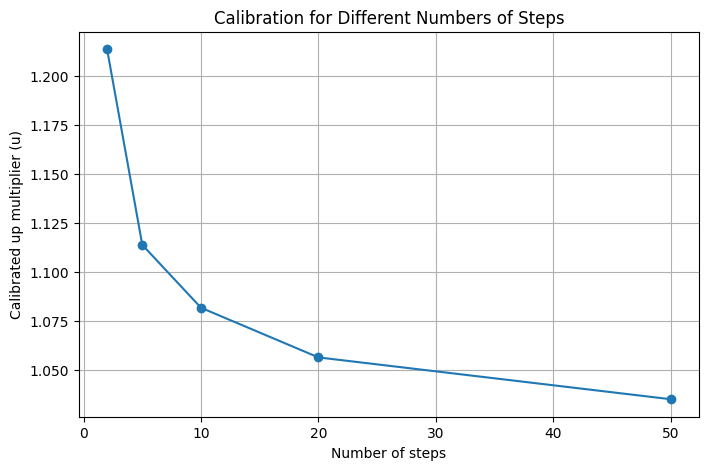

In [41]:
#Plot calibrated u against the number of steps

plt.figure(figsize=(8, 5))

plt.plot(steps_list, calibrated_u, marker="o")

plt.xlabel("Number of steps")
plt.ylabel("Calibrated up multiplier (u)")
plt.title("Calibration for Different Numbers of Steps")

plt.grid(True)
plt.show()


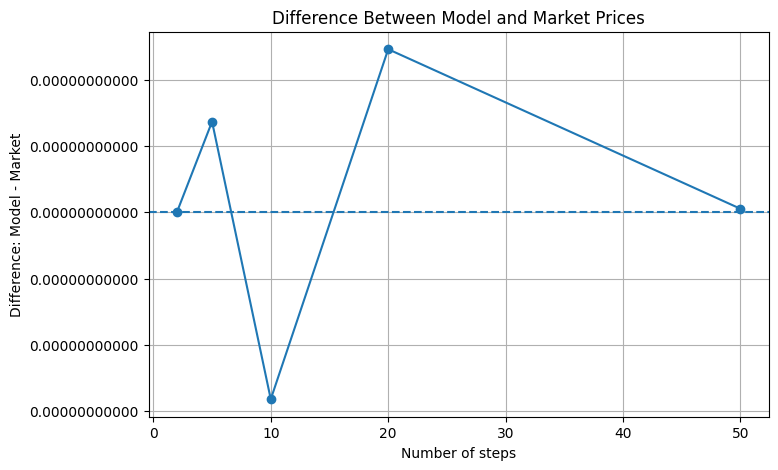

In [42]:
errors = [model_prices[i] - market_prices[i] for i in range(len(steps_list))]

plt.figure(figsize=(8, 5))
plt.plot(steps_list, errors, marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Number of steps")
plt.ylabel("Difference: Model - Market")
plt.title("Difference Between Model and Market Prices")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.grid(True)
plt.show()

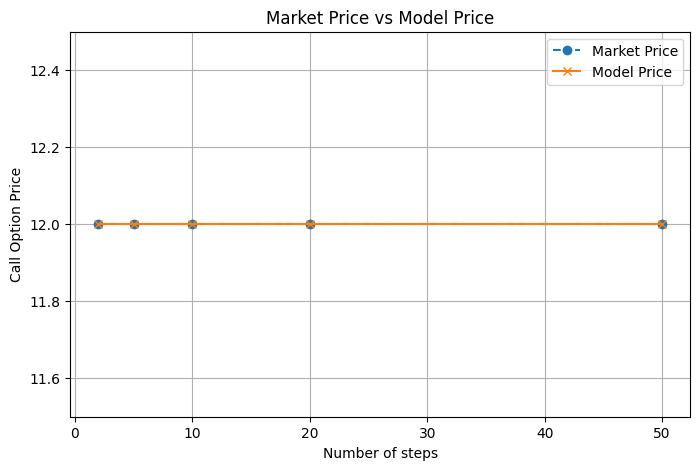

In [43]:

#Comparison of market price and model price

plt.figure(figsize=(8, 5))

plt.plot(
    steps_list,
    market_prices,
    label="Market Price",
    linestyle="--",
    marker="o"
)

plt.plot(
    steps_list,
    model_prices,
    label="Model Price",
    linestyle="-",
    marker="x"
)

#Set the Y-axis limits
plt.ylim(11.5, 12.5)

#Disable automatic axis offset
plt.ticklabel_format(style="plain", axis="y", useOffset=False)

plt.xlabel("Number of steps")
plt.ylabel("Call Option Price")
plt.title("Market Price vs Model Price")

plt.legend()
plt.grid(True)
plt.show()

#The graph compares the target market price and the model price of a European Call option for different numbers of steps (2, 5, 10, 20, and 50).

#The market price is fixed at 12, while the model price is calculated using the calibrated up multiplier for each number of steps.

#The two lines almost completely overlap, which shows that the calibration method works correctly and reproduces the target price with very small numerical errors.


In [47]:

# ==========================================
# FINAL TEST - BALANCED BINOMIAL TREE
# ==========================================

def test_all_functions():
    # Test contract parameters
    spot = 100
    K = 100
    T = 1
    r = 0.05
    market_price = 12.0

    steps_list = [2, 5, 10, 20, 50]

    #Test the European Call payoff
    assert european_call_payoff(120, 100) == 20
    assert european_call_payoff(90, 100) == 0
    print("PASS: European Call Payoff")

    #Test the stock price tree
    tree = create_spot_tree(100, 1.2, 0.8, 2)

    assert np.allclose(tree[0], [100])
    assert np.allclose(tree[1], [80, 120])
    assert np.allclose(tree[2], [64, 96, 144])
    print("PASS: Spot Tree")

    #Test the balanced down multiplier
    D = np.exp(-r * T / 2)
    u = 1.2
    d = calcBalancedDownStep(u, D)

    p_up = (1 / D - d) / (u - d)

    assert np.isclose(p_up, 0.5, atol=1e-10)
    print("PASS: Balanced Tree")

    #Test option pricing with a known result
    simple_tree = create_spot_tree(100, 1.2, 0.8, 2)
    simple_price_tree = create_discounted_price_tree(
        simple_tree, 0.95, 100
    )

    assert np.isclose(
        simple_price_tree[0][0], 15.84, atol=1e-8
    )
    print("PASS: Option Pricing")

    #Test calibration for different numbers of steps
    for steps in steps_list:

        u = calibrate(
            spot, K, T, r, steps, market_price
        )

        D = np.exp(-r * T / steps)
        d = calcBalancedDownStep(u, D)

        tree = create_spot_tree(spot, u, d, steps)
        price_tree = create_discounted_price_tree(
            tree, D, K
        )

        model_price = price_tree[0][0]
        error = abs(model_price - market_price)

        # Check that model price matches market price
        assert error < 1e-7

        #Check that multipliers satisfy the model
        assert 0 < d < 1 / D < u

        print(
            f"PASS: Steps={steps}, "
            f"u={u:.6f}, "
            f"Price={model_price:.8f}, "
            f"Error={error:.2e}"
        )

    # Test different option contracts
    contracts = [
        (100, 95, 1.0, 0.05, 12.0),
        (100, 100, 0.5, 0.03, 12.0),
        (100, 105, 1.0, 0.05, 12.0)
    ]

    for spot, K, T, r, market_price in contracts:

        steps = 20

        u = calibrate(
            spot, K, T, r, steps, market_price
        )

        D = np.exp(-r * T / steps)
        d = calcBalancedDownStep(u, D)

        tree = create_spot_tree(spot, u, d, steps)
        price = create_discounted_price_tree(
            tree, D, K
        )[0][0]

        assert abs(price - market_price) < 1e-7

        print(
            f"PASS: K={K}, T={T}, r={r}, "
            f"Model Price={price:.8f}"
        )

    print("\nALL TESTS PASSED ^=^")


#Run all tests
test_all_functions()


PASS: European Call Payoff
PASS: Spot Tree
PASS: Balanced Tree
PASS: Option Pricing
PASS: Steps=2, u=1.213687, Price=12.00000000, Error=0.00e+00
PASS: Steps=5, u=1.113791, Price=12.00000000, Error=1.37e-11
PASS: Steps=10, u=1.081690, Price=12.00000000, Error=2.82e-11
PASS: Steps=20, u=1.056350, Price=12.00000000, Error=2.46e-11
PASS: Steps=50, u=1.035004, Price=12.00000000, Error=5.44e-13
PASS: K=95, T=1.0, r=0.05, Model Price=12.00000000
PASS: K=100, T=0.5, r=0.03, Model Price=12.00000000
PASS: K=105, T=1.0, r=0.05, Model Price=12.00000000

ALL TESTS PASSED ^=^
